In [1]:
import scanpy as sc
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib
from matplotlib import rcParams
from matplotlib import rc
from matplotlib import colors
import seaborn as sb
from collections import Counter
import glob
import scimilarity

#sc.settings.set_figure_params(dpi = 160, color_map = 'RdPu', dpi_save = 300, format = 'pdf')
sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')

plt.rcParams["figure.figsize"] = [6,6]

/tmp/ipykernel_432361/155470827.py:15: FutureWarning: Use `scanpy.set_figure_params` instead
  sc.settings.set_figure_params(dpi = 160, color_map = 'RdYlBu_r', dpi_save = 300, format = 'pdf')


In [21]:
print(scimilarity.__version__)

0.4.1


In [2]:
sb.set_palette('colorblind')

In [3]:
# set working directory
%cd /nfs/team205/cs42/HSC/HSC_new_to_transfer/

/nfs/team205/cs42/HSC/HSC_new_to_transfer


In [4]:
from matplotlib import font_manager
font_manager.fontManager.addfont("csv/Helvetica.ttf")
print(font_manager.findfont("Helvetica"))
plt.rcParams["font.sans-serif"] = ["Helvetica"]
plt.rcParams["pdf.fonttype"] = 42

plt.rcParams['savefig.dpi'] = 300

plt.rcParams["axes.grid"] = False
plt.rcParams["pdf.fonttype"] = 42

/nfs/team205/cs42/HSC/HSC_new_to_transfer/csv/Helvetica.ttf


In [5]:
# figure directory
fig_path = 'figure/'
#fig_path = '/home/jovyan/mount/gdrive/HSC/chenqu_jhub/'
sc.settings.figdir = fig_path

# Load data

In [6]:
adata = sc.read('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/validation_flex_celltypist.h5ad')

In [24]:
#smad7 = adata[adata.obs['sample'].isin(['SMAD7','wild-type'])]

# SCimilarity

In [7]:
# model downloaded and saved at scimilarity_model/
# curl -L -o model_v1.1.tar.gz https://zenodo.org/records/10685499/files/model_v1.1.tar.gz?download=1
# tar -xzvf scimilarity_model/model_v1.1.tar.gz -C scimilarity_model

In [7]:
from scimilarity import CellAnnotation
from scimilarity.utils import align_dataset, lognorm_counts

## 1. preprocessing

In [8]:
# Instantiate the CellQuery object
# Set model_path to the location of the uncompressed model
model_path = "scimilarity_model/model_v1.1"
ca = CellAnnotation(model_path=model_path)

In [9]:
adata = align_dataset(adata, ca.gene_order)

## 2. Compute embedding

In [11]:
adata.obsm["X_scimilarity"] = ca.get_embeddings(adata.X)

In [12]:
sc.pp.neighbors(adata, use_rep="X_scimilarity")
sc.tl.umap(adata)

/software/cellgen/cellgeni/conda/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


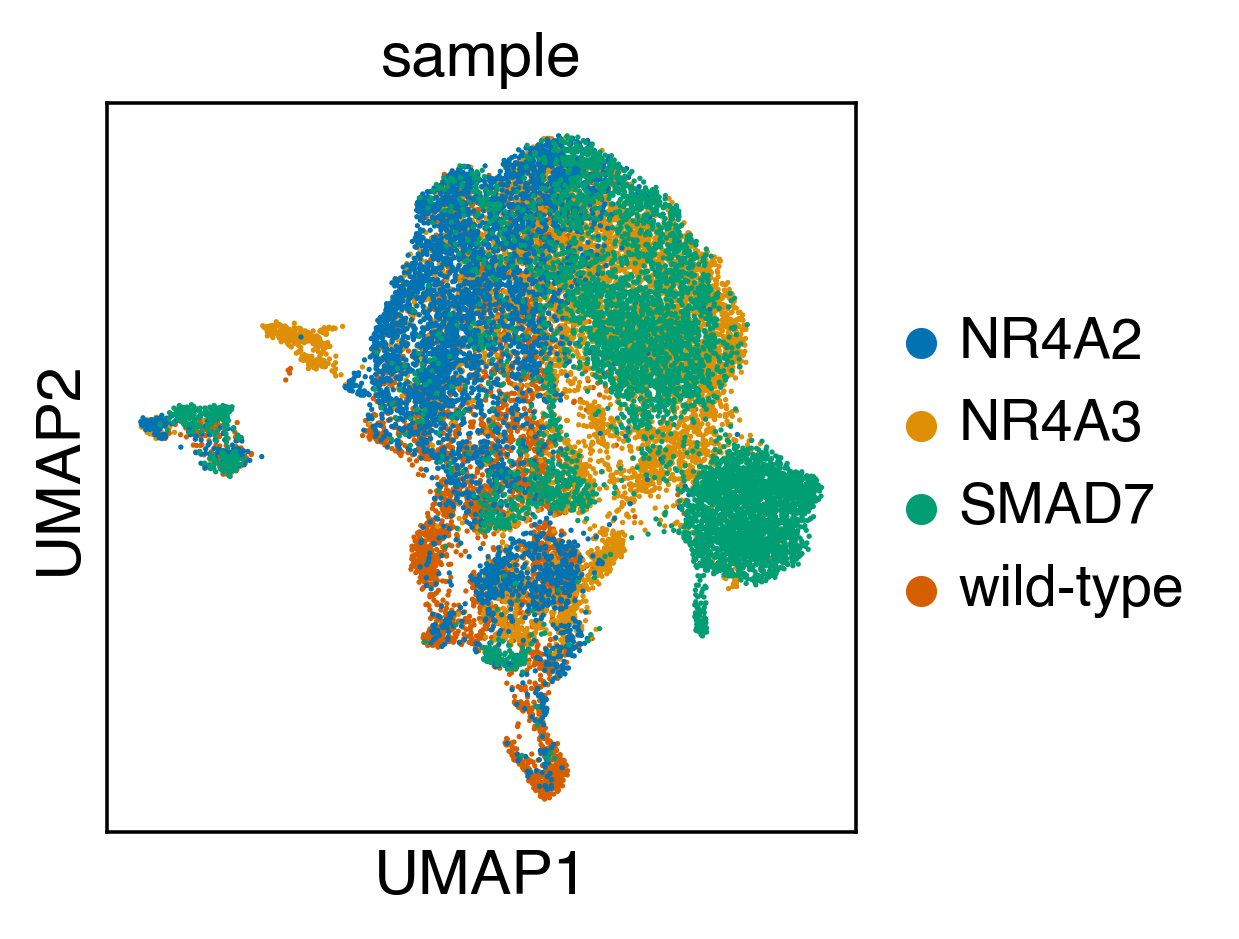

In [13]:
plt.rcParams["figure.figsize"] = [3,3]
sc.pl.umap(adata, color="sample")

## 3. Annotation

In [14]:
predictions, nn_idxs, nn_dists, nn_stats = ca.get_predictions_knn(
    adata.obsm["X_scimilarity"], weighting=True
)
adata.obs["predictions_unconstrained"] = predictions.values

Get nearest neighbors finished in: 0.11636885007222493 min


100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 20950/20950 [00:01<00:00, 15087.82it/s]


/nfs/users/nfs_c/cs42/.local/lib/python3.12/site-packages/anndata/_core/anndata.py:1257: ImplicitModificationWarning: Trying to modify attribute `.obs` of view, initializing view as actual.
  df[key] = c


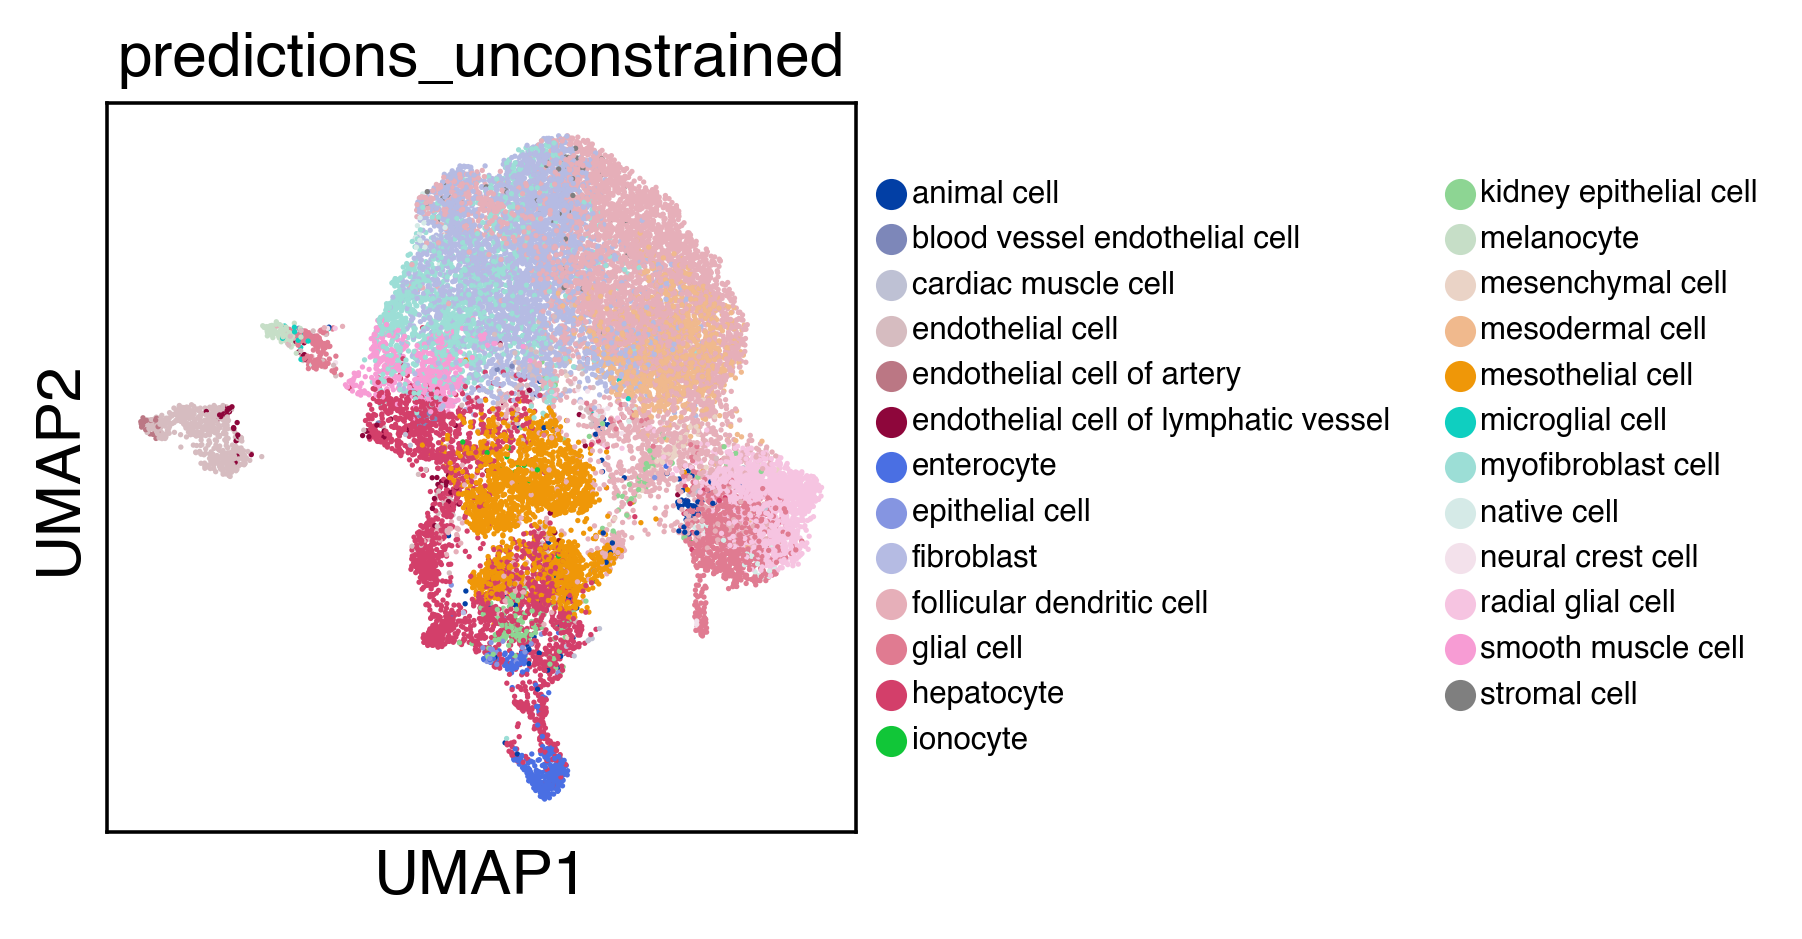

In [15]:
celltype_counts = adata.obs.predictions_unconstrained.value_counts()
well_represented_celltypes = celltype_counts[celltype_counts > 20].index

sc.pl.umap(
    adata[adata.obs.predictions_unconstrained.isin(well_represented_celltypes)],
    color="predictions_unconstrained",
    legend_fontsize=7,
)

In [16]:
adata.obs['min_dist'] = nn_dists[:, 0]

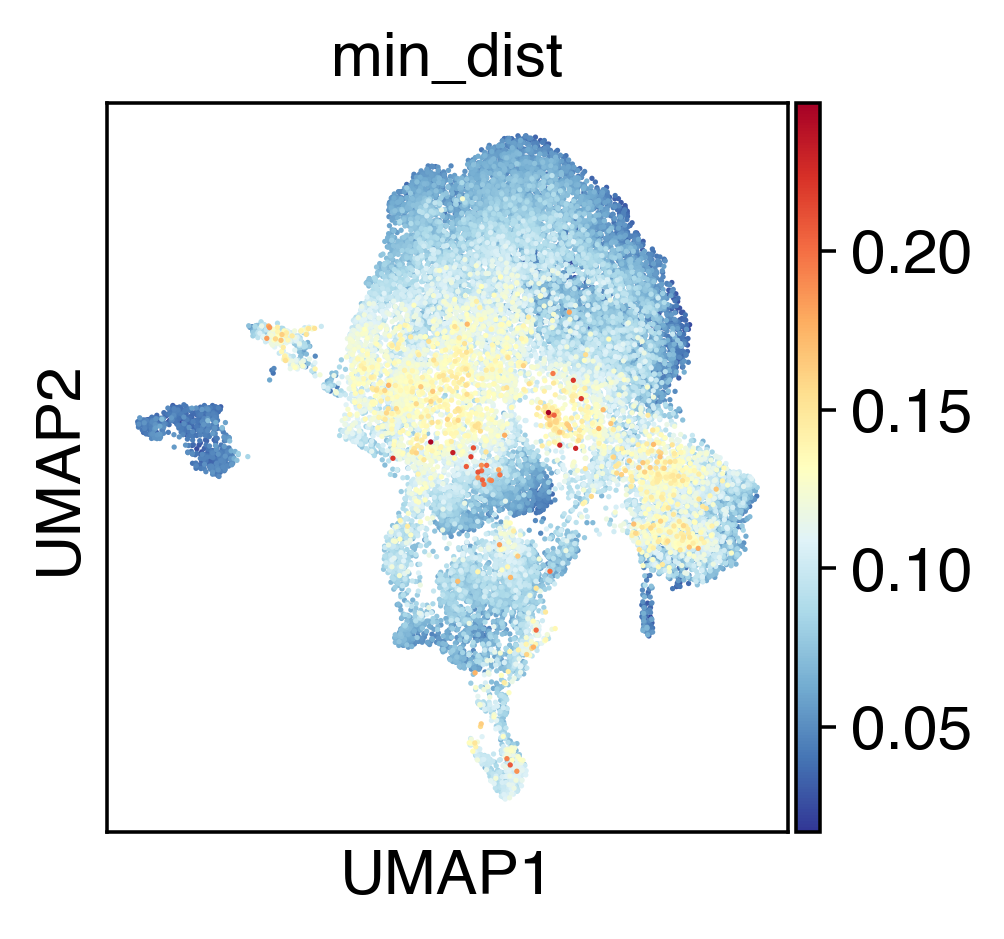

In [17]:
# min_dist represents confidence in cell type prediction. >0.05 means not confident
sc.pl.umap(adata, color="min_dist")
#plt.savefig("adams_umap_min_dist.png", dpi=300, bbox_inches="tight")

In [18]:
df = pd.crosstab(adata.obs['sample'],adata.obs["predictions_unconstrained"])
df = df.loc[:,well_represented_celltypes]
df

predictions_unconstrained,follicular dendritic cell,fibroblast,hepatocyte,mesothelial cell,myofibroblast cell,radial glial cell,mesodermal cell,glial cell,endothelial cell,smooth muscle cell,...,native cell,mesenchymal cell,stromal cell,epithelial cell,endothelial cell of artery,cardiac muscle cell,microglial cell,neural crest cell,ionocyte,blood vessel endothelial cell
sample,,,,,,,,,,,,,,,,,,,,,
NR4A2,423,1377,694,457,857,2,14,1,156,390,...,26,5,19,2,21,8,0,0,3,11
NR4A3,2631,1026,159,506,397,46,341,203,82,59,...,11,47,17,4,8,3,22,13,0,1
SMAD7,1848,430,48,353,37,1387,637,797,235,23,...,33,10,10,28,0,14,2,11,2,0
wild-type,241,1005,1470,845,214,1,14,0,189,89,...,6,3,11,2,2,2,0,0,17,9


In [19]:
adata.write_h5ad('/nfs/team205/cs42/HSC/HSC_new_to_transfer/write/validation_flex_celltypist_scimilarity.h5ad')

In [20]:
adata.obs["predictions_unconstrained"].to_csv('csv/validation_flex_scimilarity_prediction.csv')